In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## confusion-matrix

**Figure 1: Confusion matrix of the Random Forest star-rating classifier on the Yelp test set.** Each row is normalized over the reviews with that true rating, so the diagonal is per-class recall. Predictions are pulled towards the extremes: 1- and 5-star reviews are mostly correct (0.82 and 0.76), but 2-star reviews are predicted as 1-star about as often as correctly (0.38 vs 0.37), and 4-star reviews as 5-star (0.37 vs 0.39).

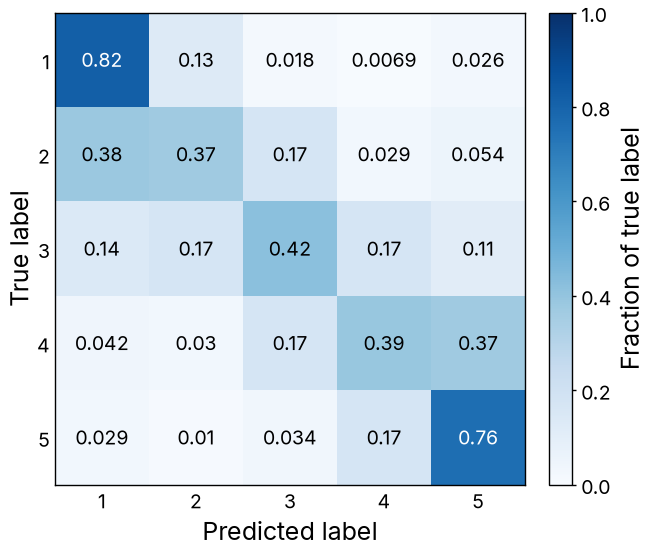

In [2]:
with open("../confusion-matrix.json") as f:
    data = json.load(f)
labels = data["labels"]
matrix = np.array(data["matrix"])

fig, ax = plt.subplots(figsize=(3.25, 3))
im = ax.imshow(matrix, aspect="auto", vmin=0, vmax=1)
# values as printed in the paper (2 significant digits); padding to 3 would invent precision
for i in range(len(labels)):
    for j in range(len(labels)):
        v = matrix[i, j]
        text_color = "white" if np.dot(im.cmap(im.norm(v))[:3], [0.299, 0.587, 0.114]) < 0.5 else "black"
        ax.text(j, i, f"{v:g}", ha="center", va="center", color=text_color)
ax.set_xticks(range(len(labels)), labels=labels)
ax.set_yticks(range(len(labels)), labels=labels)
ax.tick_params(length=0)
ax.grid(False)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
fig.colorbar(im, ax=ax, label="Fraction of true label")

fit_height(fig, ax, aspect=1.0)
fig.savefig("confusion-matrix.pdf")
fig.savefig("confusion-matrix.png")
plt.show()